<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/power_method_for_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualization of power method (for eigendecomposition, SVD)

## For details see handwritten notes.

## Eigenvectors and eigenvalues
Remember that when $Mv = av$, we say the vector $v$ is an **eigenvector**, and the number $a$ is the correspondsing **eigenvalue**.

## SVD:
Covered last time


In [ ]:
#@title
from ipywidgets import *
import ipywidgets as widgets

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as lines


from PIL import Image

## Here we just define the points we transform

In [ ]:
#@title
A = np.array([(np.sin(x), np.cos(x))
  for x in np.linspace(0,np.pi*2, 100, endpoint = False)])

c = [1,1]

P = A
# P = np.vstack((A,A*2))

## Basic power iteration algorithm

In [ ]:
def power_iteration(M, p, iters):
  '''Returns a sequence of vectors converging to
  the dominant unit eigenvector of M'''
  p = p / np.linalg.norm(p)
  ps = [p]

  for i in range(iters):
    p = M @ p
    p /= np.linalg.norm(p)
    ps.append(p)

  return np.array(ps)

# Impl

In [ ]:
#@title
def plot_powers(M, t, c = 'y'):
  if t == 0:
    return
  p = np.array((3.,4)) # a 'random' starting vector
  ps = power_iteration(M, p, t)

  for i, (x,y) in enumerate(ps):
    plt.plot([0,x], [0,y], color = c,
             zorder = 1000)

  plt.plot([0,x], [0,y], color = c, linewidth = 10,
             zorder = 1000, alpha = 0.8)

  #plt.plot(*ps.T, '-o', markersize = 5)

In [ ]:
#@title
def prod(t, U, Sm, Vt):
  '''
  t is an integer between 0 and 3, and decides how many
  'steps' of SVD are done. So 1 is just the initial rotation/reflection
  '''
  if t == 1:
    return Vt
  if t == 2:
    return Sm @ Vt
  if t == 3:
    return U @ Sm @ Vt

  return np.eye(2)

def animate(M):
  U,S,Vt = np.linalg.svd(M)
  Sm = np.diag(S)
  return lambda t: prod(t, U, Sm, Vt)

# Implementation of the visualization (not so important)

In [ ]:
#@title
import matplotlib.pyplot as plt
import matplotlib.lines as lines
import matplotlib.patches as pt

sl = lambda x : widgets.FloatSlider(value=x, min = -5., max = 5., step = 0.1)

R = np.vstack(([0,0], [0,1], [1,1], [1,0], [0,0]))

def plot_grid(A, **kw):
  k = 13
  q = 1e6
  S = np.array([(-q, x) for x in np.arange(-k,k,1)])
  E = S + np.array((2*q, 0))
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'])) for a,b in zip(S,E)]

def plot_basis(A, **kw):
  S = np.zeros((2,2))
  E = np.eye(2)
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'], lw = 3)) for a,b in zip(S,E)]


def get_ellipse_axes(M):
  U,S,Vt = np.linalg.svd(M)
  return U@np.diag(S)

def get_abs_determinant(M):
  U,S,Vt = np.linalg.svd(M)
  return np.prod(S)

def get_rank(M):
  U,S,Vt = np.linalg.svd(M)
  return np.count_nonzero(S)

def vis_transform(A,
                  grid = True, connect = True,
                  basis = True, basis_image = True, eigenv = True,
                  ellipse_axes = True,
                  larger_boxes = False,
                  dx = 0, dy = 0, many = False, T = 0):
  plt.figure(figsize = (24, 24))

 # def print(*k): pass

  #print("final matrix:", A)

  C = P + (dx, dy)

  #plt.gca().add_patch( pt.Polygon((A@R.T).T, color = 'red', alpha = 0.1) )

  #A = animate(A)(T)

  #print(f"matrix at {T}:", A)

  old_alpha = 0.1
  new_alpha = 0.5

  if basis:
    plot_basis(np.eye(2), alpha = 0.5, color = 'blue')

  if basis_image:
    plot_basis(A, alpha = 1, color = 'red')

  if grid:
    plot_grid(np.eye(2), alpha = old_alpha, color = 'blue')
    plot_grid([[0,-1],[1,0]], alpha = old_alpha, color = 'blue')
    plot_grid(A, alpha = new_alpha, color = 'red')
    plot_grid(A@[[0,-1],[1,0]], alpha = new_alpha, color = 'green')

  if larger_boxes:
    plt.gca().add_patch( pt.Polygon(3*R, color = 'blue', alpha = old_alpha) )
    plt.gca().add_patch( pt.Polygon((3*A@R.T).T, color = 'red', alpha = new_alpha/2) )

  #plt.gca().add_patch( pt.Polygon(R, color = 'blue', alpha = old_alpha*4) )
  #plt.gca().add_patch( pt.Polygon((A@R.T).T, color = 'red', alpha = new_alpha/2) )

  Q = [(1,(0,0)), (1, (0,0)), (1, (2,0)), (1, (0,2)), (1, (2,2))] if many else [(1,(0,0))]
  for a,t in Q:
    C1 = (a*C + t)
    C2 = (A@C1.T).T

    plt.scatter(C1[:,0], C1[:,1], alpha = 0.3, color = 'blue')
    plt.scatter(C2[:,0], C2[:,1], alpha = 1, color = 'red')

  if connect:
    for a,t in [(1,(0,0))]:
      C1 = (a*C + t)
      C2 = (A@C1.T).T

      for p,q in zip(C1, C2):
        plt.plot([p[0], q[0]], [p[1], q[1]], alpha=0.3, color='blue')

  U, S, Vt = np.linalg.svd(A)

  X = get_ellipse_axes(A)

  if X is not None and ellipse_axes:
    plot_basis(X, alpha = 0.9, color = 'red')
    plot_basis(-X, alpha = 0.6, color = 'red')
    plot_powers(A@A.T, T, c = 'hotpink') ################# !!!!!!!!!!


  if eigenv:
    S, E = np.linalg.eig(A)
    plot_basis(E*S, alpha = 0.9, color = 'green', linewidth = 10)
    plot_basis(-E*S, alpha = 0.9, color = 'green', linewidth = 10)
    plot_powers(A, T, c = 'springgreen') ################# !!!!!!!!!!

  #print("red box area:", np.prod(np.abs(S)))

  d = get_abs_determinant(A)
  r = get_rank(A)
  plt.title(f'|det| = {d}, rank = {r}')

  plt.axis('equal')
  plt.show()

In [ ]:
#@title
def go(grid, connect, basis, basis_image, eigenvectors, ellipse_axes, a,b,c,d, iters):
  A = np.array([[a,c],[b,d]])
  vis_transform(A, grid, connect, basis, basis_image, eigenvectors,
                ellipse_axes = ellipse_axes,
                larger_boxes = False, dx = 0, dy = 0, many = False, T = iters)

# Play with me!

We run the power iteration algorithm, starting from a (fixed) random vector. One on the matrix $M$ and then another matrix $X$ derived from $M$.

* Run on $M$ the algorithm converges to the vector undergoing greatest scaling (i.e. dominant eigenvector of $M$, which I scale by its corresponding eigenvalue).

* Run on $X$ it converges to the direction of longest axis of the ellipse which is the image of the circle under the linear transformation (here I mark the half-axis as vector $\sigma_1 u_1$ we get from SVD, which we could call the dominant left singular vector.)

> See notes to really understand what's hapenning and what this mysterious matrix $X$ is!

# Just play
with the interactive plot below, change parameter $t$ which controls the number of iterations used in the power iteration.



In [ ]:
interactive_plot = interactive(go,
                               grid = False, connect = False,
                               eigenvectors = True,
                               basis = False, basis_image = False,
                               many = False,
                               ellipse_axes = False,
                               a = sl(2), b = sl(1),
                               c = sl(-0.5), d = sl(0.5),
                               iters = widgets.IntSlider(value=0, min = 0,
                                                       max = 30, step = 1))

interactive_plot.layout.height = '1600px'
interactive_plot.layout.width = '1600px'
HBox([interactive_plot])

# Simple implementation  of truncated SVD

In [ ]:
def is_eigenvec(M, p):
  v = np.linalg.norm(M@p)
  return np.allclose((M@p)/p, v)

def my_dominant_eigenpair(M, iters=100):
  '''Returns
  the dominant unit eigenvector of M'''
  p = np.random.randn(M.shape[1])
  p = p / np.linalg.norm(p)

  for i in range(iters):
    p = M @ p
    p /= np.linalg.norm(p)

  return p, np.linalg.norm(M@p)

def my_rank_1_svd(M, iters=100):
  v, s1 = my_dominant_eigenpair(M.T@M)

  s = np.sqrt(s1)
  u = M@v / s # Mv = su
  return u, s, v

def my_truncated_svd(M0, k, power_method_iters=100):
  M = M0.copy()
  U,S,Vt = [],[],[]
  i = 0

  res = np.zeros_like(M0)

  for i in range(1, k+1):
    u,s,vt = my_rank_1_svd(M, iters=power_method_iters)
    R = s * np.outer(u, vt)
    # on the 'remaining' matrix!
    res += R

    plt.imshow(np.concatenate([M, R, res], axis=1))
    plt.suptitle("curr M | delta | result")
    plt.title(f"iter = {i}, rank of result = {np.linalg.matrix_rank(res)}")
    plt.show()

    M -= R # reduce the rank of M by 1 and iterate
    U.append(u)
    S.append(s)
    Vt.append(vt)

  return np.array(U).T, np.array(S), np.array(Vt)

# Let's try it on a simple image

In [ ]:
from keras.datasets import mnist

In [ ]:
im = mnist.load_data()[0][0][0]

In [ ]:
im

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [ ]:
original_rank = np.linalg.matrix_rank(im)

In [ ]:
original_rank

np.int64(20)

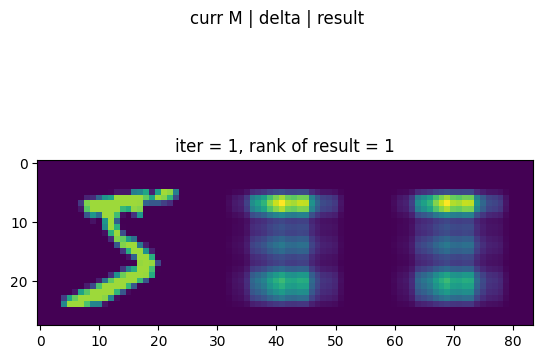

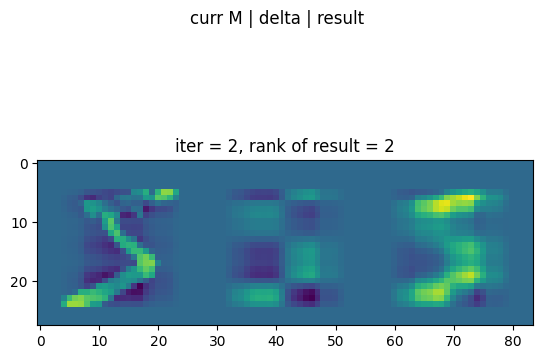

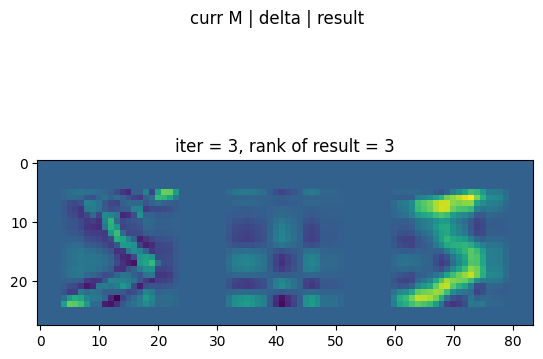

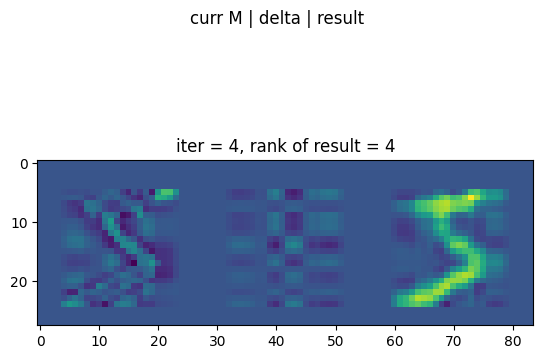

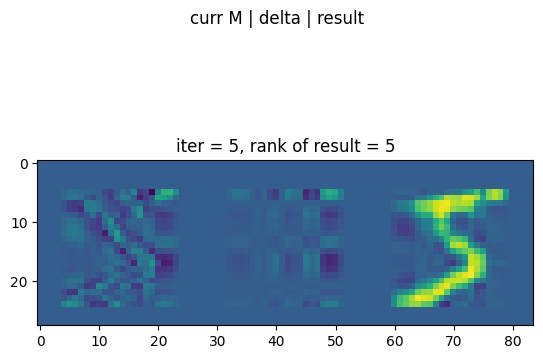

In [ ]:
# U, s, Vt = my_truncated_svd(im/255, k=original_rank+1)
U, s, Vt = my_truncated_svd(im/255, k=5)
S = np.diag(s)

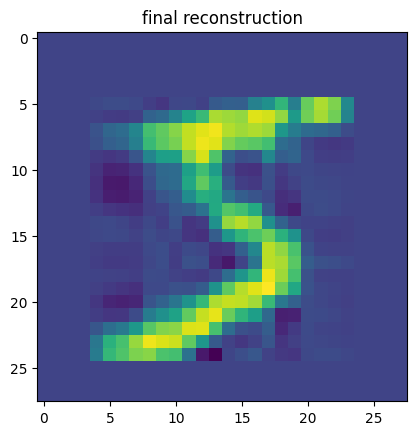

In [ ]:
plt.title('final reconstruction')
plt.imshow(U@S@Vt); # final image

In [ ]:
U.shape, Vt.shape, S.shape

((28, 5), (5, 28), (5, 5))

# Of course we can apply it to any matrix (not only images)

In [ ]:
np.random.seed(0)

In [ ]:
M = np.random.randn(4,4)

In [ ]:
print(M)

[[ 1.76405235  0.40015721  0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788  0.95008842 -0.15135721]
 [-0.10321885  0.4105985   0.14404357  1.45427351]
 [ 0.76103773  0.12167502  0.44386323  0.33367433]]


In [ ]:
np.linalg.matrix_rank(M)

np.int64(4)

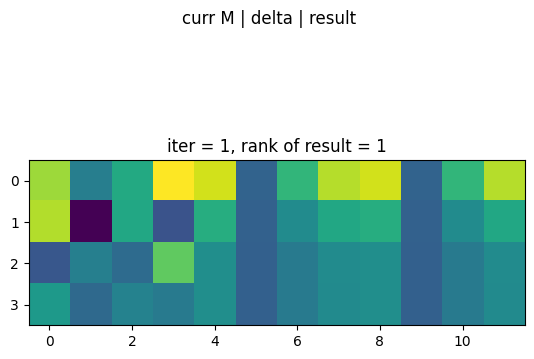

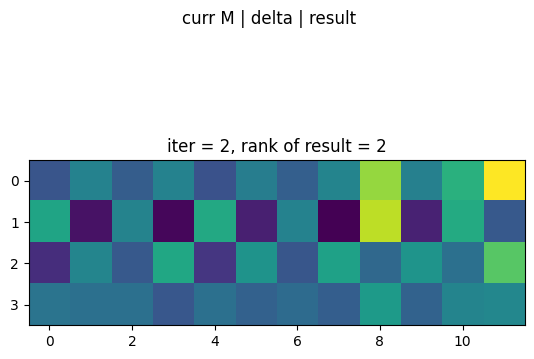

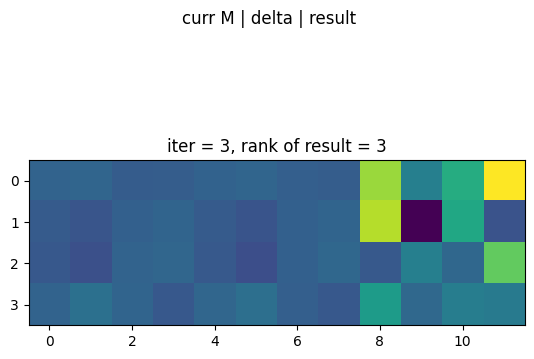

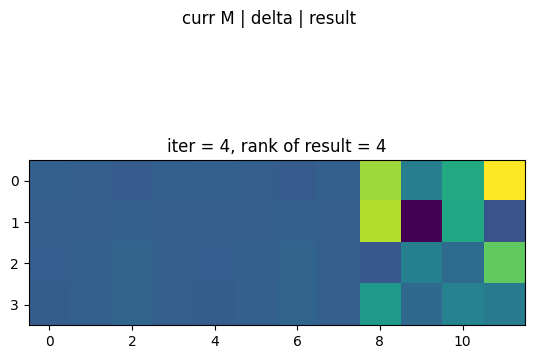

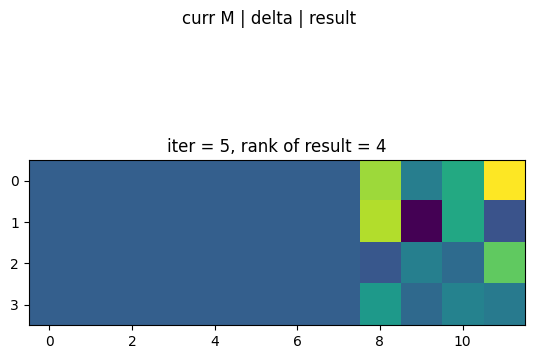

In [ ]:
mU,mS,mVt = my_truncated_svd(M, k=5, power_method_iters=50)